# v4 — the "shadow" drawdown overlay

Run the strategy (v3.1) untouched as a **shadow**; trade a **real** book that de-risks when the
*shadow's* equity is in a sustained drawdown and re-enters when the shadow recovers. The switch — both
trigger and recovery — is keyed off the **shadow's** untouched equity (the flat traded book could
never signal recovery). We (1) validate the **portfolio-level** overlay and (2) test whether
**per-asset** shadows do better. Everything via `lab.py` (engine-parity-checked).

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'
import sys; from pathlib import Path
_p = Path.cwd().resolve()
ROOT = next((q for q in [_p, *_p.parents] if (q/'pyproject.toml').exists()), _p)
sys.path[:0] = [str(ROOT)]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import research.funding_carry.lab as H
from src.common import config as cfg
plt.rcParams.update({'figure.figsize':(14,3.8),'axes.grid':True,'grid.alpha':0.25,
                     'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
NAVY,TEAL,AMBER,RED,GREY='#1f3a5f','#2a9d8f','#e0a32e','#c1121f','0.6'
COSTS=cfg.load_config('strategies/funding_carry/v3.1.yaml')['costs']
maj,non=H.universe(); P=H.load_panels(maj+non); didx=P['didx']
SPECS=[{'name':'funding_vol','window':30},{'name':'neg_freq','window':30},{'name':'basis','window':30}]
VETO=[{'feature':'funding_vol','direction':'max','cap':0.75},{'feature':'neg_freq','direction':'max','cap':0.40},{'feature':'basis','direction':'max','cap':0.01}]
sh=H.evaluate_select(P,7,0.08,0.02,None,None,COSTS,feature_specs=SPECS,veto_rules=VETO,size_kind='inv_basis_vol',band=0.5,warmup_days=30)
Wsh=sh['W']; r_sh=sh['net'].dropna()
def kpi(res):
    r=res['net'].dropna(); e=(1+r).cumprod(); d=e/e.cummax()-1; ann=r.mean()*365
    return {'net%':round(ann*100,1),'Sharpe':res['1.0x']['sharpe'],'maxDD%':round(d.min()*100,1),
            'Calmar':round(ann/abs(d.min()),1),'2022%':round(((1+r[r.index.year==2022]).prod()-1)*100,1),
            'turn':round(res['1.0x']['ann_turnover'],0),'UW%':round((d<-1e-6).mean()*100,0)}
def eq(res): return (1+res['net'].dropna()).cumprod()
print('shadow (v3.1) loaded:', kpi(sh))

shadow (v3.1) loaded: {'net%': np.float64(9.9), 'Sharpe': 6.316, 'maxDD%': np.float64(-2.8), 'Calmar': np.float64(3.5), '2022%': np.float64(-2.0), 'turn': 20.0, 'UW%': np.float64(61.0)}


## 1. The drawdown is a long, shallow *regime* — and it persists

v3.1's max drawdown is only −2.8%, but it's **underwater 61% of the time**, with a single 2022
episode that ran ~16 months (peak 2022-01 → recovered 2023-05). And at the *regime* horizon the
drawdown **persists** — being underwater predicts much weaker forward returns (not a fast bounce):

maxDD -2.8% | underwater 61% of days | longest run 483d (1.3y)
  fwd-10d ret: underwater +0.08%  vs surfaced +0.55%
  fwd-30d ret: underwater +0.30%  vs surfaced +1.42%
  fwd-60d ret: underwater +0.69%  vs surfaced +2.53%


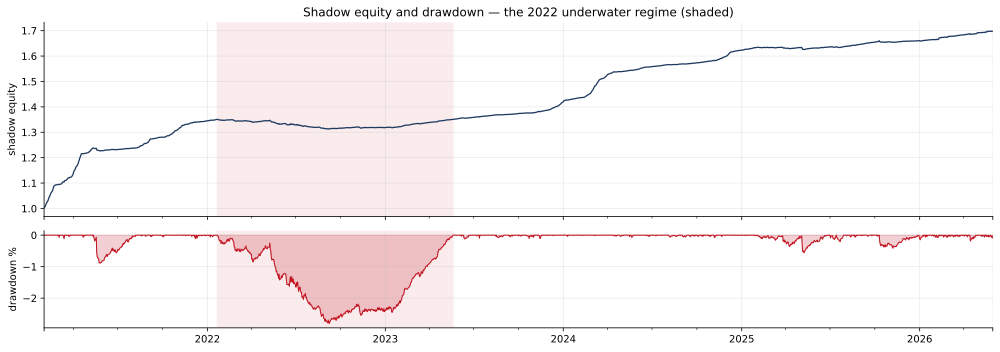

In [2]:
dd=H.drawdown(r_sh)
uw=(dd<-1e-6); runs=(uw!=uw.shift()).cumsum(); longest=int(uw.groupby(runs).sum().max())
print(f"maxDD {dd.min()*100:.1f}% | underwater {uw.mean()*100:.0f}% of days | longest run {longest}d ({longest/365:.1f}y)")
for k in (10,30,60):
    fwd=r_sh[::-1].rolling(k,min_periods=k//2).sum()[::-1].shift(-1)
    print(f"  fwd-{k}d ret: underwater {fwd[uw].mean()*100:+.2f}%  vs surfaced {fwd[~uw].mean()*100:+.2f}%")
fig,(a1,a2)=plt.subplots(2,1,figsize=(14,5),sharex=True,gridspec_kw={'height_ratios':[2,1]})
eq(sh).plot(ax=a1,color=NAVY,lw=1.3); a1.set_ylabel('shadow equity'); a1.set_title('Shadow equity and drawdown — the 2022 underwater regime (shaded)')
a1.axvspan(pd.Timestamp('2022-01-21'),pd.Timestamp('2023-05-20'),color=RED,alpha=0.08)
(dd*100).plot(ax=a2,color=RED,lw=1.0); a2.fill_between(dd.index,dd*100,0,color=RED,alpha=0.2); a2.set_ylabel('drawdown %')
a2.axvspan(pd.Timestamp('2022-01-21'),pd.Timestamp('2023-05-20'),color=RED,alpha=0.08); plt.tight_layout(); plt.show()

## 2. Portfolio-level overlay — it works

Switch on the *shadow's* drawdown, calibrated **point-in-time** as percentiles of its own DD history
(exit at the 15th pct, re-enter at the 50th; expanding window). Same net return, but the deep part of
2022 is sat out: **maxDD −2.8%→−0.9%, Calmar 3.5→11**, and turnover drops (no trading while flat).

                 net%  Sharpe  maxDD%  Calmar  2022%  turn   UW%
v3.1 always-in    9.9   6.316    -2.8     3.5   -2.0  20.0  61.0
overlay binary    9.8   6.601    -0.9    11.1   -0.0  14.0  62.0
overlay partial   9.6   6.456    -1.5     6.4   -1.1  15.0  63.0


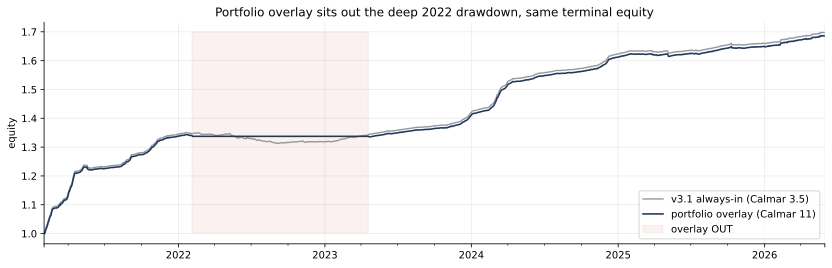

In [3]:
state=H.overlay_state(dd, qexit=0.15, qreenter=0.50, lookback=252, expanding=True)  # binary, point-in-time
port=H.book(Wsh.mul(state,axis=0),P,COSTS,warmup_days=30)
# partial de-risk: smooth exposure between the two percentiles
Qe=dd.expanding(min_periods=252).quantile(0.15); Qr=dd.expanding(min_periods=252).quantile(0.50)
partexp=((dd-Qe)/(Qr-Qe)).clip(0,1).fillna(1.0); part=H.book(Wsh.mul(partexp,axis=0),P,COSTS,warmup_days=30)
print(pd.DataFrame({'v3.1 always-in':kpi(sh),'overlay binary':kpi(port),'overlay partial':kpi(part)}).T.to_string())
fig,ax=plt.subplots(figsize=(14,4))
eq(sh).plot(ax=ax,color=GREY,lw=1.4,label='v3.1 always-in (Calmar 3.5)')
eq(port).plot(ax=ax,color=NAVY,lw=1.6,label='portfolio overlay (Calmar 11)')
ax.fill_between(state.index, eq(sh).min(), eq(sh).max(), where=(state.reindex(state.index)<0.5), color=RED, alpha=0.06, label='overlay OUT')
ax.set_ylabel('equity'); ax.legend(); ax.set_title('Portfolio overlay sits out the deep 2022 drawdown, same terminal equity'); plt.show()

**Robustness + placebo.** The result is a plateau, not a spike — a broad range of exit/re-enter
percentiles all help — and timed exits beat *random* exits of the same out-fraction (so it's timing,
not just being out). Caveats: the benefit rests on ~one episode (2022); in benign years the overlay
stays inactive (identical to v3.1); and it's blind in its first ~year (needs history to calibrate).

In [4]:
rows={}
for qe_ in (0.10,0.15,0.20):
    for qr_ in (0.50,0.60):
        s=H.overlay_state(dd,qexit=qe_,qreenter=qr_,lookback=252); r=H.book(Wsh.mul(s,axis=0),P,COSTS,warmup_days=30)
        rows[f'exit{int(qe_*100)}/re{int(qr_*100)}']={'Calmar':kpi(r)['Calmar'],'maxDD%':kpi(r)['maxDD%'],'net%':kpi(r)['net%']}
print('robustness (exit/re-enter percentiles):'); print(pd.DataFrame(rows).T.to_string())
# placebo: random OUT, matched out-fraction & mean spell
out=(state<0.5).to_numpy(); frac=out.mean()
sp=[]; c=0
for v in out:
    if v: c+=1
    elif c: sp.append(c); c=0
ms=np.mean(sp) if sp else 20; rng=np.random.default_rng(0); cals=[]
for _ in range(20):
    e=np.ones(len(didx)); i=0
    while i<len(didx):
        if rng.random()<frac/max(ms,1): L=int(rng.exponential(ms)); e[i:i+L]=0; i+=L
        else: i+=1
    rr=H.book(Wsh.mul(pd.Series(e,index=didx),axis=0),P,COSTS,warmup_days=30); cals.append(kpi(rr)['Calmar'])
print(f"\nplacebo (random OUT matched {frac:.0%}): Calmar mean {np.mean(cals):.1f}  vs timed overlay {kpi(port)['Calmar']}")

robustness (exit/re-enter percentiles):
             Calmar  maxDD%  net%
exit10/re50    11.0    -0.9   9.8
exit10/re60    11.0    -0.9   9.7
exit15/re50    11.1    -0.9   9.8
exit15/re60    11.0    -0.9   9.8
exit20/re50    11.1    -0.9   9.8
exit20/re60    11.0    -0.9   9.8



placebo (random OUT matched 23%): Calmar mean 4.3  vs timed overlay 11.1


## 3. Per-asset shadows — this FAILS

Instead of one switch on the book, give **each name** its own shadow drawdown and gate its position
individually. It backfires badly: **net 9.9%→3.6%, maxDD doubles to −9.7%, turnover ~2×.**

                   net%  Sharpe  maxDD%  Calmar  2022%  turn   UW%
v3.1 always-in      9.9   6.316    -2.8     3.5   -2.0  20.0  61.0
portfolio overlay   9.8   6.601    -0.9    11.1   -0.0  14.0  62.0
per-asset shadows   3.6   2.349    -9.7     0.4   -5.4  38.0  91.0


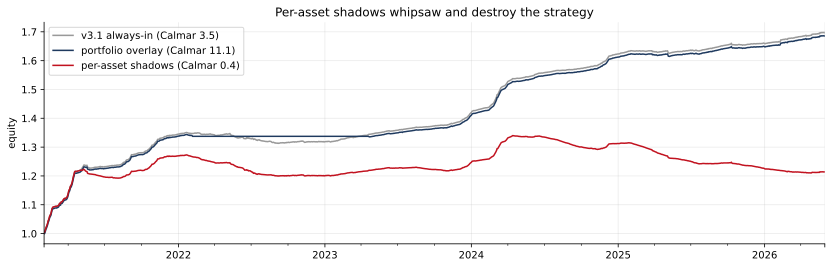

In [5]:
R=P['F']+P['L']                                             # per-name daily P&L (funding + basis)
dda=H.drawdown(R)                                            # each name's own drawdown
sa=H.overlay_state(dda, qexit=0.15, qreenter=0.50, lookback=252, expanding=False)  # per-name state
pa=H.book(Wsh.mul(sa),P,COSTS,warmup_days=30)               # cut names -> cash
print(pd.DataFrame({'v3.1 always-in':kpi(sh),'portfolio overlay':kpi(port),'per-asset shadows':kpi(pa)}).T.to_string())
fig,ax=plt.subplots(figsize=(14,4))
for lab_,res,c in [('v3.1 always-in',sh,GREY),('portfolio overlay',port,NAVY),('per-asset shadows',pa,RED)]:
    eq(res).plot(ax=ax,color=c,lw=1.5,label=f'{lab_} (Calmar {kpi(res)["Calmar"]})')
ax.set_ylabel('equity'); ax.legend(); ax.set_title('Per-asset shadows whipsaw and destroy the strategy'); plt.show()

**Why per-asset fails:** a single name's P&L drawdown is dominated by **idiosyncratic,
mean-reverting basis noise** (we measured basis returns as ~uncorrelated and stationary). Gating on it
sells at the local bottom and re-buys after the bounce — a whipsaw, per name, ~2× the turnover. The
**persistent** drawdown signal only exists at the **aggregate**, where the basis noise averages out
and the slow funding-*regime* component dominates. Aggregation is what makes the drawdown tradeable.

## Conclusion — v4 = portfolio-level shadow overlay

- **Ship the portfolio overlay** (binary, point-in-time percentile DD switch, exit ~p15 / re-enter
  ~p50): same net return, **maxDD −2.8%→−0.9%, Calmar 3.5→11**, sits out the 2022 dead regime, lower
  turnover, beats the random-exit placebo, robust to the percentile choice, causal.
- **Asymmetric safety layer:** it's inactive when there's no drawdown (identical to v3.1 in 2024–26),
  so shipping it is low-risk; the only exposure is a false de-risk, which the regime-persistence and
  placebo argue is not systematic.
- **Caveats:** the benefit rests on ~one drawdown episode (2022) and it's blind in its first ~year —
  it earns full trust as more drawdowns accrue.
- **Per-asset shadows do NOT work** — the drawdown signal is only tradeable at the portfolio level;
  per name it's idiosyncratic basis noise and whipsaws. So the overlay is a **portfolio-level** layer.